In [1]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ===============================
# 1. Import Libraries
# ===============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import RandomForestRegressor

In [4]:
# ===============================
# 2. Load Dataset
# ===============================
df = pd.read_csv('synthetic_online_retail_data.csv')

In [5]:
df.head(5)

,customer_id,order_date,product_id,category_id,category_name,product_name,quantity,price,payment_method,city,review_score,gender,age
0,13542,2024-12-17,784,10,Electronics,Smartphone,2,373.36,Credit Card,New Oliviaberg,1.0,F,56
1,23188,2024-06-01,682,50,Sports & Outdoors,Soccer Ball,5,299.34,Credit Card,Port Matthew,NaN,M,59
2,55098,2025-02-04,684,50,Sports & Outdoors,Tent,5,23.00,Credit Card,West Sarah,5.0,F,64
3,65208,2024-10-28,204,40,Books & Stationery,Story Book,2,230.11,Bank Transfer,Hernandezburgh,5.0,M,34
4,63872,2024-05-10,202,20,Fashion,Skirt,4,176.72,Credit Card,Jenkinshaven,1.0,F,33


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     1000 non-null   int64  
 1   order_date      1000 non-null   object 
 2   product_id      1000 non-null   int64  
 3   category_id     1000 non-null   int64  
 4   category_name   1000 non-null   object 
 5   product_name    1000 non-null   object 
 6   quantity        1000 non-null   int64  
 7   price           1000 non-null   float64
 8   payment_method  1000 non-null   object 
 9   city            1000 non-null   object 
 10  review_score    799 non-null    float64
 11  gender          897 non-null    object 
 12  age             1000 non-null   int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB


In [7]:
# ===============================
# 3. Data Cleaning
# ===============================

In [8]:
# Convert date column
df['order_date'] = pd.to_datetime(df['order_date'])

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     1000 non-null   int64         
 1   order_date      1000 non-null   datetime64[ns]
 2   product_id      1000 non-null   int64         
 3   category_id     1000 non-null   int64         
 4   category_name   1000 non-null   object        
 5   product_name    1000 non-null   object        
 6   quantity        1000 non-null   int64         
 7   price           1000 non-null   float64       
 8   payment_method  1000 non-null   object        
 9   city            1000 non-null   object        
 10  review_score    799 non-null    float64       
 11  gender          897 non-null    object        
 12  age             1000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(5), object(5)
memory usage: 101.7+ KB


In [10]:
# Remove missing values
df = df.dropna()

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 721 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     721 non-null    int64         
 1   order_date      721 non-null    datetime64[ns]
 2   product_id      721 non-null    int64         
 3   category_id     721 non-null    int64         
 4   category_name   721 non-null    object        
 5   product_name    721 non-null    object        
 6   quantity        721 non-null    int64         
 7   price           721 non-null    float64       
 8   payment_method  721 non-null    object        
 9   city            721 non-null    object        
 10  review_score    721 non-null    float64       
 11  gender          721 non-null    object        
 12  age             721 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(5), object(5)
memory usage: 78.9+ KB


In [12]:
df.isnull().sum()

customer_id       0
order_date        0
product_id        0
category_id       0
category_name     0
product_name      0
quantity          0
price             0
payment_method    0
city              0
review_score      0
gender            0
age               0
dtype: int64

In [13]:
df.isnull().sum().sum()

0

In [14]:
# Remove negative or zero quantity/price
df = df[(df['quantity'] > 0) & (df['price'] > 0)]

In [15]:
# Create Total Sales
df['Total_Sales'] = df['quantity'] * df['price']

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 721 entries, 0 to 999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     721 non-null    int64         
 1   order_date      721 non-null    datetime64[ns]
 2   product_id      721 non-null    int64         
 3   category_id     721 non-null    int64         
 4   category_name   721 non-null    object        
 5   product_name    721 non-null    object        
 6   quantity        721 non-null    int64         
 7   price           721 non-null    float64       
 8   payment_method  721 non-null    object        
 9   city            721 non-null    object        
 10  review_score    721 non-null    float64       
 11  gender          721 non-null    object        
 12  age             721 non-null    int64         
 13  Total_Sales     721 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(5), object(5)
memory us

In [17]:
# Explore the data
# UNIVARIATE ANALYSIS

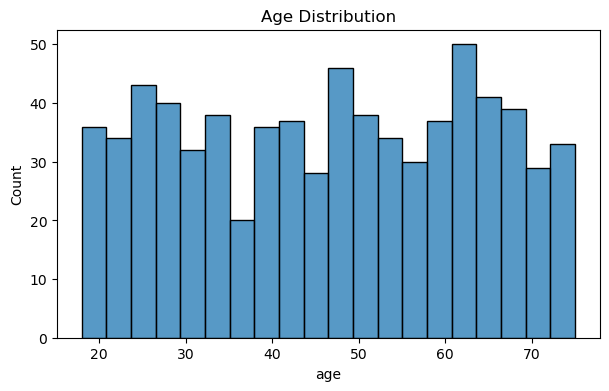

In [18]:
# Age Distribution

plt.figure(figsize=(7,4))

sns.histplot(df["age"], bins=20)

plt.title("Age Distribution")

plt.show()

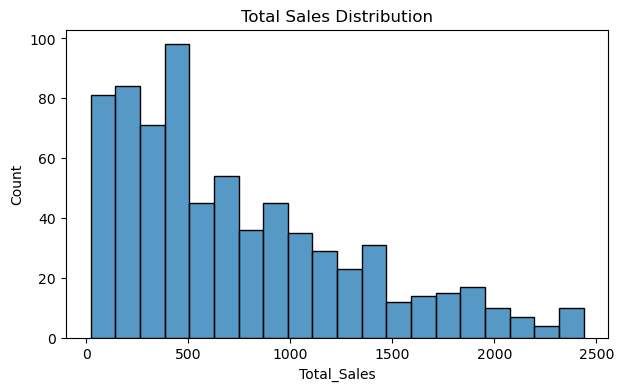

In [19]:
# TOTAL SALES DISTRIBUTION
# -----------------------------------------------------

plt.figure(figsize=(7,4))

sns.histplot(df["Total_Sales"], bins=20)

plt.title("Total Sales Distribution")

plt.show()

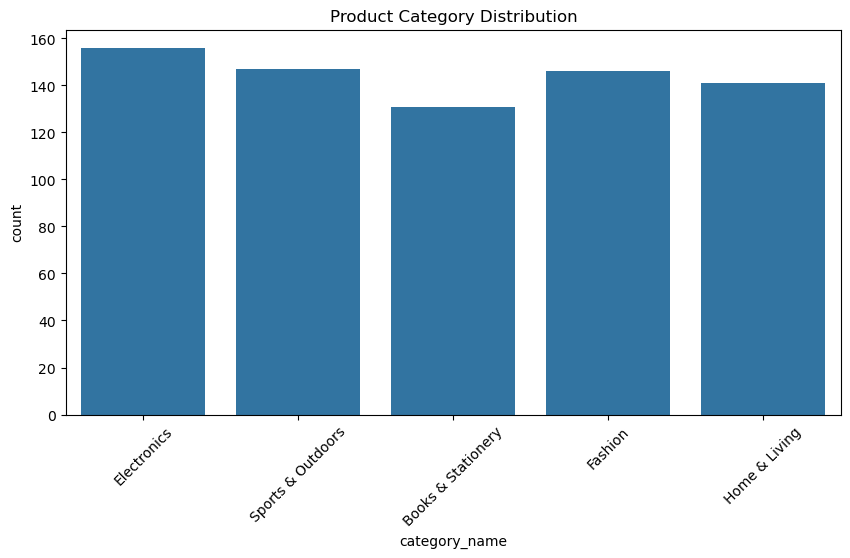

In [20]:
# Product Category Count
# -----------------------------------------------------

plt.figure(figsize=(10,5))

sns.countplot(x='category_name', data=df)

plt.xticks(rotation=45)

plt.title("Product Category Distribution")

plt.show()

In [21]:
# BIVARIATE ANALYSIS
# -----------------------------------------------------

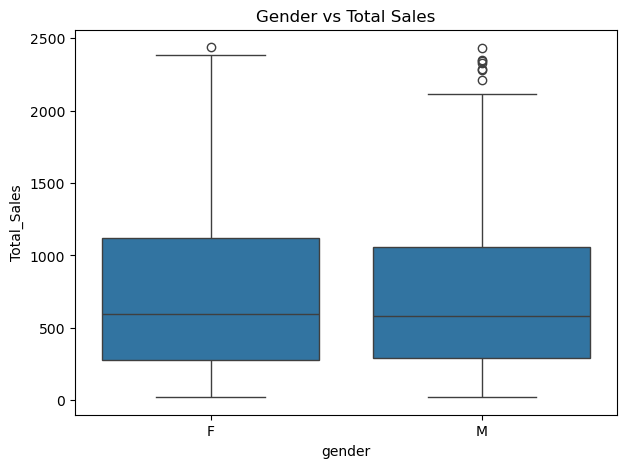

In [22]:
# Gender vs Total Sales

plt.figure(figsize=(7,5))

sns.boxplot(x=df["gender"], y=df["Total_Sales"])

plt.title("Gender vs Total Sales")

plt.show()

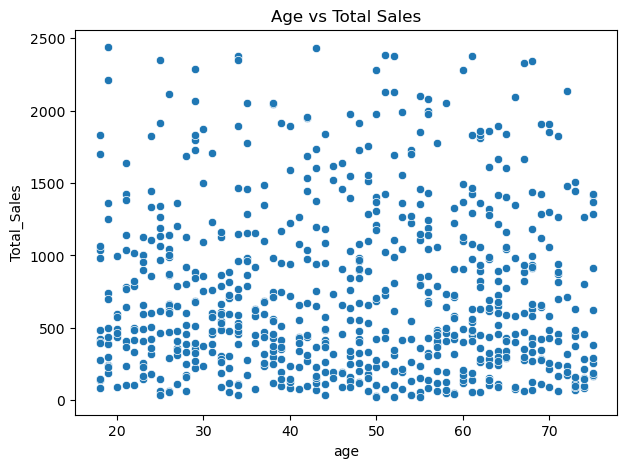

In [23]:
# AGE VS TOTAL SALES
# -----------------------------------------------------

plt.figure(figsize=(7,5))

sns.scatterplot(x=df["age"], y=df["Total_Sales"])

plt.title("Age vs Total Sales")

plt.show()

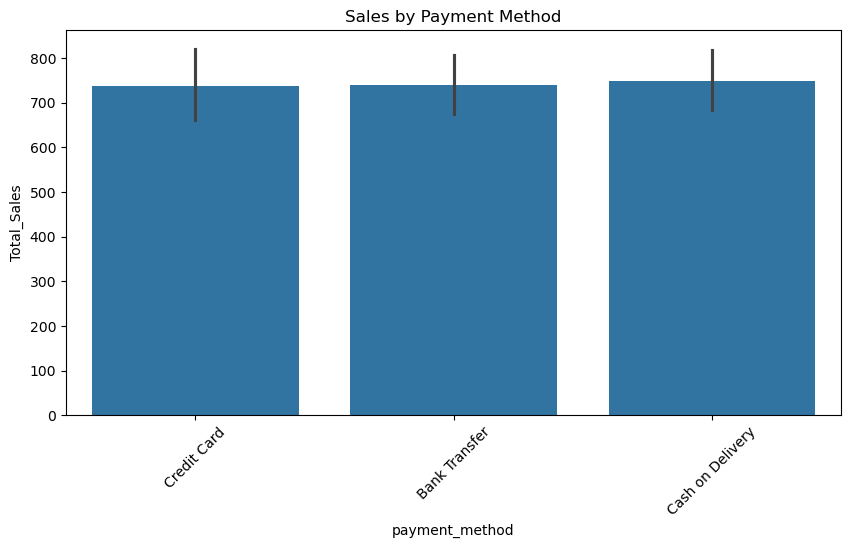

In [24]:
# Sales by Payment Method
plt.figure(figsize=(10,5))
sns.barplot(x='payment_method', y='Total_Sales', data=df)
plt.title("Sales by Payment Method")
plt.xticks(rotation=45)
plt.show()

In [25]:
# 6. CORRELATION ANALYSIS
# =====================================================

In [26]:
# Select numerical columns
num_df = df.select_dtypes(include=np.number)

In [27]:
# Create correlation matrix
corr = num_df.corr()

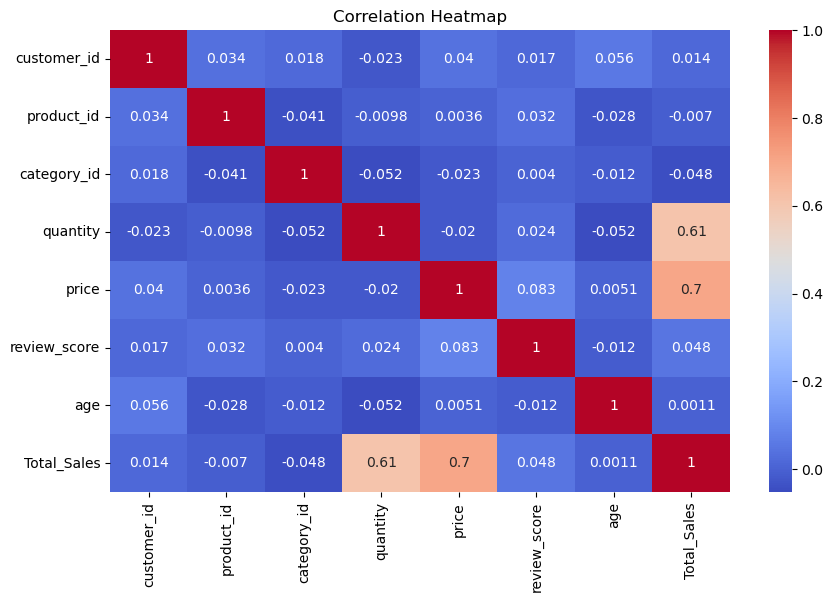

In [28]:
# Plot heatmap
plt.figure(figsize=(10,6))

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [29]:
# 7. RFM ANALYSIS
# =====================================================

In [30]:
# Create snapshot date
snapshot_date = df["order_date"].max() + pd.Timedelta(days=1)

In [31]:
# Create RFM table

rfm = df.groupby("customer_id").agg({

    "order_date": lambda x: (snapshot_date - x.max()).days,

    "customer_id": "count",

    "Total_Sales": "sum"

})

In [32]:
# Rename columns

rfm.columns = ["Recency", "Frequency", "Monetary"]


In [33]:
rfm.head()

,Recency,Frequency,Monetary
customer_id,,,
10211,240,1,65.02
10254,191,1,70.93
10299,113,1,815.76
10486,188,1,548.20
10539,3,1,34.64


In [34]:
# Get the relevant columns for clustering

relevant_cols = ["age", "price", "quantity", "Total_Sales"]
df = df[relevant_cols]
df.head()


,age,price,quantity,Total_Sales
0,56,373.36,2,746.72
2,64,23.00,5,115.00
3,34,230.11,2,460.22
4,33,176.72,4,706.88
5,21,196.16,4,784.64


In [35]:
# 8. FEATURE SCALING
# =====================================================

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)


In [36]:
# Data Transformation

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(df)
scaled_data = scaler.transform(df)

In [37]:
#Determine the optimal number of clusters (ELBOW METHOD)
# ============================================================

def find_best_clusters(df, maximum_K):
    clusters_centers = []
    k_values = []
    for k in range(1, maximum_K):
        kmeans_model = KMeans(n_clusters = k)
        kmeans_model.fit(df)
        clusters_centers.append(kmeans_model.inertia_)
        k_values.append(k)
    return clusters_centers, k_values



In [38]:
def generate_elbow_plot(clusters_centers, k_values):
    figure = plt.subplots(figsize = (10, 3))
    plt.plot(k_values, clusters_centers, 'o-', color = 'orange')
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Cluster Inertia")
    plt.title("Elbow Plot of KMeans")
    plt.show()

C:\Users\18022\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\18022\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\18022\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\18022\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Window

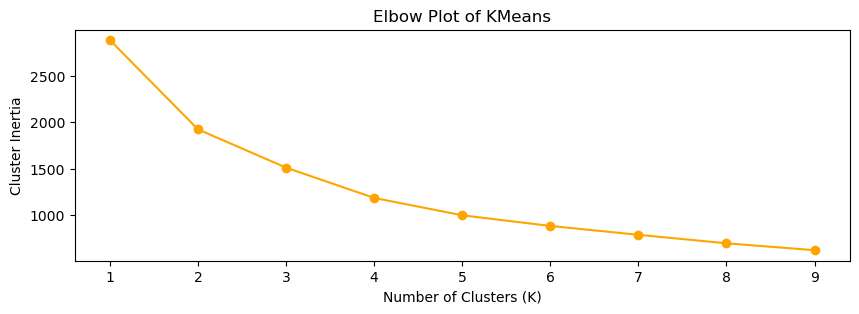

In [39]:
clusters_centers, k_values = find_best_clusters(scaled_data, 10)

generate_elbow_plot(clusters_centers, k_values)


In [40]:
# Create the final KMeans model

kmeans_model = KMeans(n_clusters = 5)

kmeans_model.fit(scaled_data)

C:\Users\18022\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [41]:
df["n_clusters"]= kmeans_model.labels_
df.head()

,age,price,quantity,Total_Sales,n_clusters
0,56,373.36,2,746.72,4
2,64,23.00,5,115.00,3
3,34,230.11,2,460.22,1
4,33,176.72,4,706.88,3
5,21,196.16,4,784.64,3


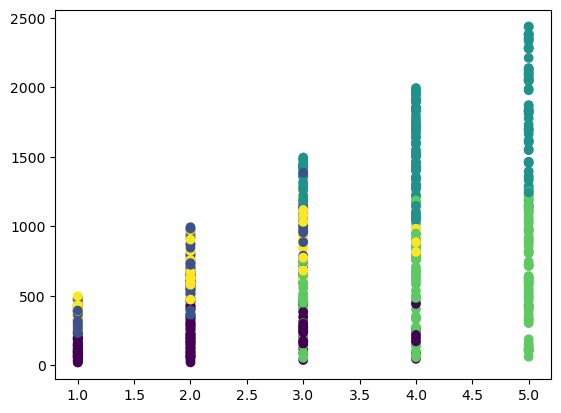

In [42]:
# Visualise the clusters

plt.scatter(df["quantity"], 
            df["Total_Sales"],
            c = df["n_clusters"])

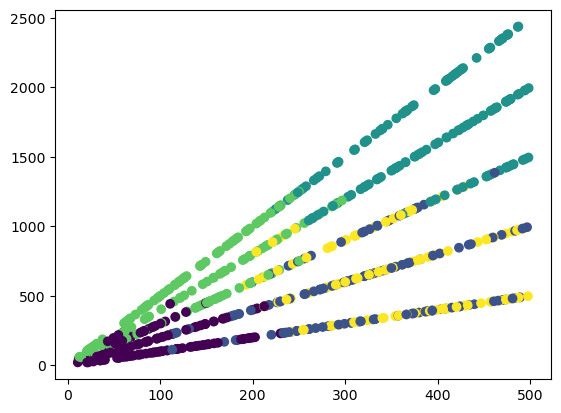

In [43]:
plt.scatter(df["price"], 
            df["Total_Sales"],
            c = df["n_clusters"])

In [44]:
df.to_csv("MOCK PROJECT 1_Retail Customer Segmentation & Sales Optimization.csv",index="FALSE")